# Solution 1: MFCC + Support Vector Machine

This notebook builds the traditional machine-learning baseline for the ESC - 50 environmental sound classification dataset. 

For every audio recording:
1. MFCC Features are extracted
2. The mean and standard deviation of each MFCC are calculated. 
3. A Support Vector Machine is trained using the extracted features
4. Performance is evaluated using the five official ESC-50 folds. 

The results include accuracy, precision, recall, macro F1 Score, class-wise F1 Scores, and a confusion matrix.

## 1. Imports and configuration

This section imports the required Python libraries and defines the main experiment settings.

The configuration values are kept together so that they can be changed easily. 

In [35]:
from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf

from scipy.fft import dct
from scipy.signal import lfilter, resample_poly, stft

from sklearn.metrics import (
    accuracy_score, 
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from tqdm.auto import tqdm

#Reproducibility and audio settings
RANDOM_SEED = 42
SAMPLE_RATE = 22050
N_MFCC = 20


# Values considered during inner cross-validation
K_BEST_OPTIONS = [40, 60, 80, 100]
SVM_C_OPTIONS = [1.0, 10.0, 30.0, 100.0]

SVM_GAMMA_OPTIONS = ["scale", 0.001, 0.01,]

# detect the project folder
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

#Dataset paths
DATASET_ROOT = PROJECT_ROOT / "data" / "ESC-50"
AUDIO_DIR = DATASET_ROOT / "audio"
METADATA_PATH = DATASET_ROOT / "meta" / "esc50.csv" 

#Output folder
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "solution1_mfcc_svm"
OUTPUT_DIR.mkdir(parents = True, exist_ok = True)

#Plot appearance
sns.set_theme (style = "whitegrid")

print("Project Folder:", PROJECT_ROOT)
print("Metadata found:", METADATA_PATH.exists())
print("Audio folder found:", AUDIO_DIR.exists())
print("Output folder:", OUTPUT_DIR)

Project Folder: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50
Metadata found: True
Audio folder found: True
Output folder: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm


## 2. Load and inspect the ESC-50 Metadata

ESC-50 contains:
- 2000 environmental audio recordings
- 50 sound classes
- 40 recordings per class
- Five predefined cross-validation folds
- Five-second audio recordings

The official folds are used instead of randomly splitting the dataset. This makes the experiment reproducible and prevents recordings from the same original source from appearing in both training and testing data. 

In [36]:
assert METADATA_PATH.exists(), f"Metadata file not found at {METADATA_PATH}"
assert AUDIO_DIR.exists(), f"Audio directory not found at {AUDIO_DIR}"

metadata = pd.read_csv(METADATA_PATH)
metadata = (
    metadata
    .sort_values(["fold", "filename"])
    .reset_index(drop = True)
)

assert len(metadata) == 2000, f"Expected 2000 clips, but found {len(metadata)}"
assert metadata["category"].nunique() == 50, ("Expected 50 sound classes.")

display(metadata.head())

print(f"Number of clips: {len(metadata):,}")
print(f"Number of classes: {metadata['category'].nunique()}")
print(f"Official folds: {sorted(metadata['fold'].unique())}")

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


Number of clips: 2,000
Number of classes: 50
Official folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 3. MFCC Feature Extraction

Mel-Frequency Cepstral Coefficients, of MFCCs, are commonly used to represent the frequency characteristics of audio. 

The extraction process performs the following operations:

1. Load the audio recording
2. Convert stereo audio to mono if necessary.
3. Resample the audio to 22,050 Hz.
4. Normalise its amplitude
5. Apply a pre-emphasis filter
6. Calculate the Short - Time Fourier Transform
7. Convert the power spectrum to the Mel frequency scale.
8. Apply a logarithm to the Mel energies.
9. Apply the Discrete Cosine Transform to obtain MFCCs.

Twenty MFCC coefficients are extracted. The mean and standard deviation of each coefficient are then calculated across time.

This produces a fixed feature vector containing 40 values for every audio recording:

- 20 MFCC means
- 20 MFCC standard deviations

The extracted features are cached in the output folder. Therefore, feature extraction does not need to be repeated every time the notebook is run.

In [37]:
def hz_to_mel(frequency):
    """Convert a frequency from Hertz to the Mel scale."""

    return 2595.0 * np.log10(
        1.0 + frequency / 700.0
    )


def mel_to_hz(mel):
    """Convert a value from the Mel scale to Hertz."""

    return 700.0 * (
        10.0 ** (mel / 2595.0) - 1.0
    )


def create_mel_filterbank(
    sample_rate,
    n_fft,
    n_filters=40,
):
    """Create a triangular Mel filter bank."""

    mel_points = np.linspace(
        hz_to_mel(0),
        hz_to_mel(sample_rate / 2),
        n_filters + 2,
    )

    frequency_points = mel_to_hz(
        mel_points
    )

    bins = np.floor(
        (n_fft + 1)
        * frequency_points
        / sample_rate
    ).astype(int)

    filters = np.zeros(
        (
            n_filters,
            n_fft // 2 + 1,
        )
    )

    for index in range(
        1,
        n_filters + 1,
    ):
        left = bins[index - 1]
        center = bins[index]
        right = bins[index + 1]

        if center > left:
            filters[
                index - 1,
                left:center,
            ] = (
                np.arange(left, center) - left
            ) / (center - left)

        if right > center:
            filters[
                index - 1,
                center:right,
            ] = (
                right - np.arange(center, right)
            ) / (right - center)

    return filters


def prepare_audio(
    audio_path,
    sample_rate=SAMPLE_RATE,
):
    """Load, resample, convert to mono and normalize audio."""

    signal, original_rate = sf.read(
        audio_path,
        dtype="float32",
        always_2d=False,
    )

    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    if original_rate != sample_rate:
        common_factor = np.gcd(
            original_rate,
            sample_rate,
        )

        signal = resample_poly(
            signal,
            sample_rate // common_factor,
            original_rate // common_factor,
        )

    peak = np.max(np.abs(signal))

    if peak > 0:
        signal = signal / peak

    return signal.astype(np.float32)


def extract_features_from_signal(
    signal,
    sample_rate=SAMPLE_RATE,
    n_mfcc=N_MFCC,
):
    """
    Extract static MFCC, delta MFCC and delta-delta MFCC
    summary features.

    The output contains 120 features:
    20 coefficients × 3 representations × 2 statistics.
    """

    signal = lfilter(
        [1.0, -0.97],
        [1.0],
        signal,
    )

    n_fft = 1024

    _, _, spectrum = stft(
        signal,
        fs=sample_rate,
        window="hann",
        nperseg=551,
        noverlap=331,
        nfft=n_fft,
        boundary=None,
    )

    power = (
        np.abs(spectrum) ** 2
    ) / n_fft

    mel_filterbank = create_mel_filterbank(
        sample_rate,
        n_fft,
    )

    mel_energies = (
        mel_filterbank @ power
    )

    log_mel = np.log(
        np.maximum(
            mel_energies,
            np.finfo(float).eps,
        )
    )

    mfcc = dct(
        log_mel,
        type=2,
        axis=0,
        norm="ortho",
    )[1:n_mfcc + 1]

    # First-order temporal changes
    mfcc_delta = np.gradient(
        mfcc,
        axis=1,
    )

    # Second-order temporal changes
    mfcc_delta_delta = np.gradient(
        mfcc_delta,
        axis=1,
    )

    feature_groups = [
        mfcc,
        mfcc_delta,
        mfcc_delta_delta,
    ]

    summary_features = []

    for feature_group in feature_groups:
        summary_features.extend(
            [
                feature_group.mean(axis=1),
                feature_group.std(axis=1),
            ]
        )

    return np.concatenate(
        summary_features
    ).astype(np.float32)


def extract_mfcc_features(
    audio_path,
):
    """Extract all MFCC-based features from an audio file."""

    signal = prepare_audio(
        audio_path
    )

    return extract_features_from_signal(
        signal
    )


# Use a new filename so the old 40-feature cache is not loaded
FEATURE_CACHE = (
    OUTPUT_DIR
    / "mfcc_delta_deltadelta_120_features_v2.npz"
)

if FEATURE_CACHE.exists():
    cached_features = np.load(
        FEATURE_CACHE
    )

    X = cached_features["X"]
    y = cached_features["y"]
    folds = cached_features["folds"]

    print(
        "Loaded cached enhanced features:",
        FEATURE_CACHE,
    )

else:
    feature_rows = []

    for filename in tqdm(
        metadata["filename"],
        desc="Extracting enhanced MFCC features",
    ):
        features = extract_mfcc_features(
            AUDIO_DIR / filename
        )

        feature_rows.append(
            features
        )

    X = np.asarray(
        feature_rows,
        dtype=np.float32,
    )

    y = metadata["target"].to_numpy(
        dtype=np.int64
    )

    folds = metadata["fold"].to_numpy(
        dtype=np.int64
    )

    np.savez_compressed(
        FEATURE_CACHE,
        X=X,
        y=y,
        folds=folds,
    )

    print(
        "Saved enhanced feature cache:",
        FEATURE_CACHE,
    )

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Fold array shape:", folds.shape)

assert X.shape == (2000, 120)
assert np.isfinite(X).all()

Extracting enhanced MFCC features:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved enhanced feature cache: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm\mfcc_delta_deltadelta_120_features_v2.npz
Feature matrix shape: (2000, 120)
Label array shape: (2000,)
Fold array shape: (2000,)


## 4. Nested feature selection and official five-fold evaluation

Every recording is represented by 120 MFCC-based summary features:

- 20 static MFCC means
- 20 static MFCC standard deviations
- 20 delta MFCC means
- 20 delta MFCC standard deviations
- 20 delta-delta MFCC means
- 20 delta-delta MFCC standard deviations

Delta features represent the rate at which the MFCC values change over time. Delta-delta features represent changes in those rates.

The model applies `SelectKBest` with the ANOVA F-test to retain the most discriminative features.

The number of selected features and the SVM hyperparameters are chosen using inner cross-validation. This process occurs using only the four outer training folds.

The held-out official test fold is not used for:

- Feature selection
- Hyperparameter selection
- Feature scaling
- Model training

This nested procedure reduces the risk of overfitting to the official test folds.

In [38]:
all_predictions = np.empty_like(y)

fold_results = []

trained_models = {}

best_parameters_by_fold = {}

# Inner cross-validation used only within each outer training set
inner_cross_validation = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_SEED,
)

parameter_grid = {
    "feature_selection__k": K_BEST_OPTIONS,
    "svm__C": SVM_C_OPTIONS,
    "svm__gamma": SVM_GAMMA_OPTIONS,
}

for test_fold in sorted(
    np.unique(folds)
):
    print("\n" + "=" * 60)
    print(
        f"Outer test fold: {test_fold}"
    )
    print("=" * 60)

    train_mask = folds != test_fold
    test_mask = folds == test_fold

    X_train = X[train_mask]
    X_test = X[test_mask]

    y_train = y[train_mask]
    y_test = y[test_mask]

    base_pipeline = Pipeline(
        [
            (
                "feature_selection",
                SelectKBest(
                    score_func=f_classif,
                    k=60,
                ),
            ),
            (
                "scaler",
                StandardScaler(),
            ),
            (
                "svm",
                SVC(
                    kernel="rbf",
                ),
            ),
        ]
    )

    search = GridSearchCV(
        estimator=base_pipeline,
        param_grid=parameter_grid,
        scoring="accuracy",
        cv=inner_cross_validation,
        n_jobs=1,
        refit=True,
        verbose=0,
    )

    start_time = time.perf_counter()

    search.fit(
        X_train,
        y_train,
    )

    # The best pipeline is chosen without using the test fold
    model = search.best_estimator_

    predictions = model.predict(
        X_test
    )

    elapsed_time = (
        time.perf_counter()
        - start_time
    )

    all_predictions[
        test_mask
    ] = predictions

    trained_models[
        int(test_fold)
    ] = model

    best_parameters_by_fold[
        int(test_fold)
    ] = search.best_params_

    fold_accuracy = accuracy_score(
        y_test,
        predictions,
    )

    fold_precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0,
    )

    fold_recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0,
    )

    fold_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0,
    )

    fold_results.append(
        {
            "fold": int(test_fold),
            "accuracy": fold_accuracy,
            "macro_precision": fold_precision,
            "macro_recall": fold_recall,
            "macro_f1": fold_f1,
            "selected_features": (
                search.best_params_[
                    "feature_selection__k"
                ]
            ),
            "best_C": (
                search.best_params_[
                    "svm__C"
                ]
            ),
            "best_gamma": str(
                search.best_params_[
                    "svm__gamma"
                ]
            ),
            "train_and_predict_seconds": elapsed_time,
        }
    )

    print(
        "Best parameters:",
        search.best_params_,
    )

    print(
        f"Test accuracy: {fold_accuracy:.4f}"
    )

fold_results = pd.DataFrame(
    fold_results
)

display(
    fold_results.round(4)
)

print("Mean numerical performance:")

display(
    fold_results
    .mean(numeric_only=True)
    .to_frame("five_fold_mean")
    .round(4)
)


Outer test fold: 1
Best parameters: {'feature_selection__k': 80, 'svm__C': 30.0, 'svm__gamma': 0.01}
Test accuracy: 0.4750

Outer test fold: 2
Best parameters: {'feature_selection__k': 80, 'svm__C': 10.0, 'svm__gamma': 'scale'}
Test accuracy: 0.4750

Outer test fold: 3
Best parameters: {'feature_selection__k': 80, 'svm__C': 100.0, 'svm__gamma': 0.01}
Test accuracy: 0.5650

Outer test fold: 4
Best parameters: {'feature_selection__k': 80, 'svm__C': 10.0, 'svm__gamma': 'scale'}
Test accuracy: 0.5950

Outer test fold: 5
Best parameters: {'feature_selection__k': 80, 'svm__C': 30.0, 'svm__gamma': 'scale'}
Test accuracy: 0.5250


,fold,accuracy,macro_precision,macro_recall,macro_f1,selected_features,best_C,best_gamma,train_and_predict_seconds
0,1,0.475,0.5101,0.475,0.4699,80,30.0,0.01,17.6052
1,2,0.475,0.5394,0.475,0.4707,80,10.0,scale,16.6639
2,3,0.565,0.5755,0.565,0.5556,80,100.0,0.01,16.9965
3,4,0.595,0.6246,0.595,0.5781,80,10.0,scale,17.1335
4,5,0.525,0.5457,0.525,0.5154,80,30.0,scale,17.3275


Mean numerical performance:


,five_fold_mean
fold,3.0000
accuracy,0.5270
macro_precision,0.5591
macro_recall,0.5270
macro_f1,0.5180
selected_features,80.0000
best_C,36.0000
train_and_predict_seconds,17.1453


## 5. Selected MFCC feature analysis

The feature selector is fitted separately during every official fold experiment. Therefore, the exact features selected may differ slightly between folds.

The following analysis records:

- Which features were selected in each fold
- How many folds selected each feature
- The mean ANOVA F-score of each selected feature

A feature selected in all five folds can be considered consistently informative for ESC-50 classification.

In [40]:
# The first 20 columns contain MFCC means.
# The final 20 columns contain MFCC standard deviations.

from numpy.strings import index


feature_names = (
    [
        f"MFCC_{index +1}_mean"
        for index in range(N_MFCC)
    ]
    + [
        f"MFCC_{index +1}_std"
        for index in range(N_MFCC)
    ]
    + [
        f"MFCC_{index +1}_delta_mean"
        for index in range(N_MFCC)
    ]
    +[
        f"MFCC_{index +1}_delta_std"
        for index in range(N_MFCC)
    ]
    +[ 
        f"MFCC_{index +1}_delta_delta_mean"
        for index in range(N_MFCC)
    ]
    +[ 
        f"MFCC_{index +1}_delta_delta_std"
        for index in range(N_MFCC)
    ]
   
)

assert len(feature_names) == X.shape[1]
selected_feature_records = []

for fold_number, model in trained_models.items():

    selector = model.named_steps[
        "feature_selection"
    ]

    selected_mask = selector.get_support()

    selected_feature_names = np.asarray(
        feature_names
    )[selected_mask]

    selected_feature_scores = (
        selector.scores_[selected_mask]
    )

    for feature_name, feature_score in zip(
        selected_feature_names,
        selected_feature_scores,
    ):
        selected_feature_records.append(
            {
                "fold": fold_number,
                "feature": feature_name,
                "anova_f_score": feature_score,
            }
        )

selected_features_df = pd.DataFrame(
    selected_feature_records
)

feature_selection_summary = (
    selected_features_df
    .groupby("feature")
    .agg(
        selected_in_folds=(
            "fold",
            "nunique",
        ),
        mean_anova_f_score=(
            "anova_f_score",
            "mean",
        ),
    )
    .sort_values(
        [
            "selected_in_folds",
            "mean_anova_f_score",
        ],
        ascending=False,
    )
)

display(
    feature_selection_summary
    .head(20)
    .round(3)
)

feature_selection_summary.to_csv(
    OUTPUT_DIR
    / "selected_features_summary.csv"
)

selected_features_df.to_csv(
    OUTPUT_DIR
    / "selected_features_by_fold.csv",
    index=False,
)

,selected_in_folds,mean_anova_f_score
feature,,
MFCC_18_std,5,35.855
MFCC_15_std,5,35.194
MFCC_1_delta_delta_std,5,34.528
MFCC_19_std,5,33.339
MFCC_14_std,5,33.234
MFCC_16_std,5,33.192
MFCC_1_delta_std,5,32.819
MFCC_1_mean,5,32.569
MFCC_2_std,5,32.496


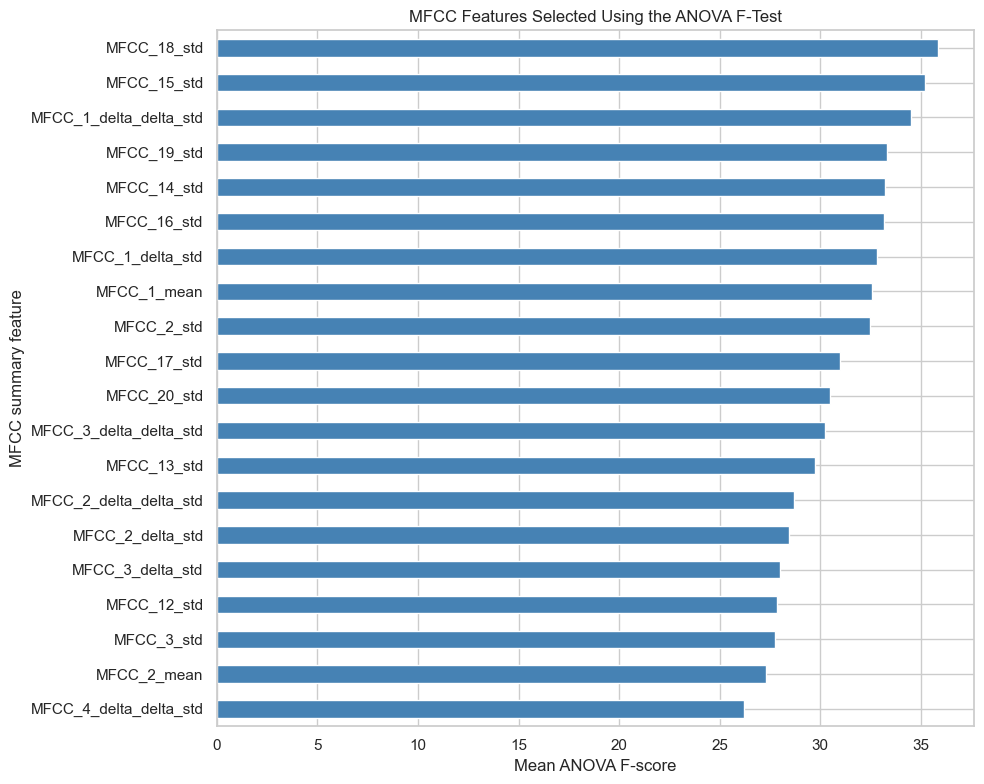

In [41]:
top_selected_features = (
    feature_selection_summary
    .head(20)
    .sort_values(
        "mean_anova_f_score"
    )
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

top_selected_features[
    "mean_anova_f_score"
].plot.barh(
    ax=ax,
    color="steelblue",
)

ax.set(
    title="MFCC Features Selected Using the ANOVA F-Test",
    xlabel="Mean ANOVA F-score",
    ylabel="MFCC summary feature",
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "selected_mfcc_features.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 6. Overall performance metrics

Predictions from all five test folds are combined to calculate the overall performance of the MFCC and SVM solution.

The following measurements are reported:

- **Accuracy:** Percentage of recordings classified correctly.
- **Macro precision:** Average precision across all 50 classes.
- **Macro recall:** Average recall across all 50 classes.
- **Macro F1 score:** Average F1 score across all 50 classes.

Macro averaging gives every sound class equal importance, regardless of its individual performance.

In [42]:
# Obtain class names in target-number order
class_names = (
    metadata[
        [
            "target",
            "category",
        ]
    ]
    .drop_duplicates()
    .sort_values("target")["category"]
    .tolist()
)

overall_metrics = {
    "accuracy": accuracy_score(
        y,
        all_predictions,
    ),
    "macro_precision": precision_score(
        y,
        all_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_recall": recall_score(
        y,
        all_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y,
        all_predictions,
        average="macro",
        zero_division=0,
    ),
}

overall_metrics_table = pd.Series(
    overall_metrics,
    name="score",
).to_frame()

display(
    overall_metrics_table.round(4)
)

report = classification_report(
    y,
    all_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T

# Save numerical results
fold_results.to_csv(
    OUTPUT_DIR / "fold_metrics.csv",
    index=False,
)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

with open(
    OUTPUT_DIR / "overall_metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        overall_metrics,
        file,
        indent=2,
    )

# Save every trained fold model
for fold_number, model in trained_models.items():
    joblib.dump(
        model,
        OUTPUT_DIR
        / f"mfcc_svm_fold_{fold_number}.joblib",
    )

print("Results saved to:", OUTPUT_DIR)

,score
accuracy,0.5270
macro_precision,0.5327
macro_recall,0.5270
macro_f1,0.5239


Results saved to: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm


## 7. Accuracy comparison across folds

This graph compares classification accuracy across the five official ESC-50 test folds.

Variation between folds indicates that the recording conditions or sound examples in some folds may be more difficult to classify than others.

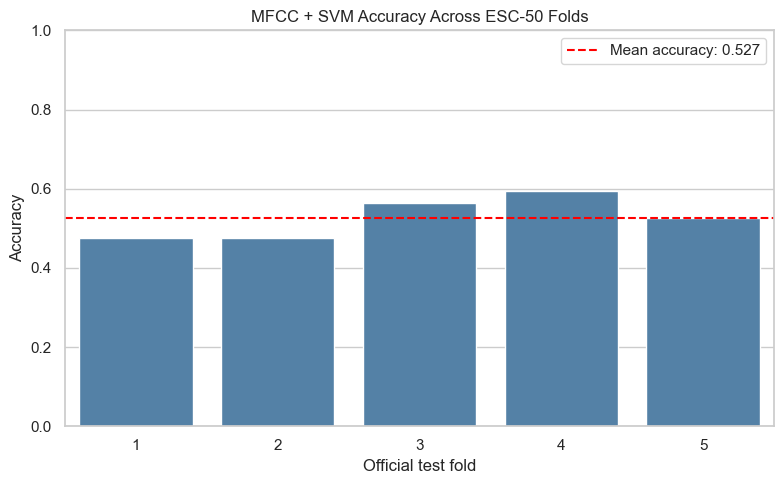

In [43]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

sns.barplot(
    data=fold_results,
    x="fold",
    y="accuracy",
    color="steelblue",
    ax=ax,
)

mean_accuracy = fold_results["accuracy"].mean()

ax.axhline(
    mean_accuracy,
    color="red",
    linestyle="--",
    label=f"Mean accuracy: {mean_accuracy:.3f}",
)

ax.set(
    title="MFCC + SVM Accuracy Across ESC-50 Folds",
    xlabel="Official test fold",
    ylabel="Accuracy",
    ylim=(0, 1),
)

ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "fold_accuracy.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 8. Confusion matrix

The confusion matrix shows which sound classes are classified correctly and which classes are confused with one another.

Each row represents the true sound class, while each column represents the class predicted by the SVM.

The matrix is normalized by the true class. Therefore, every row represents proportions between 0 and 1.

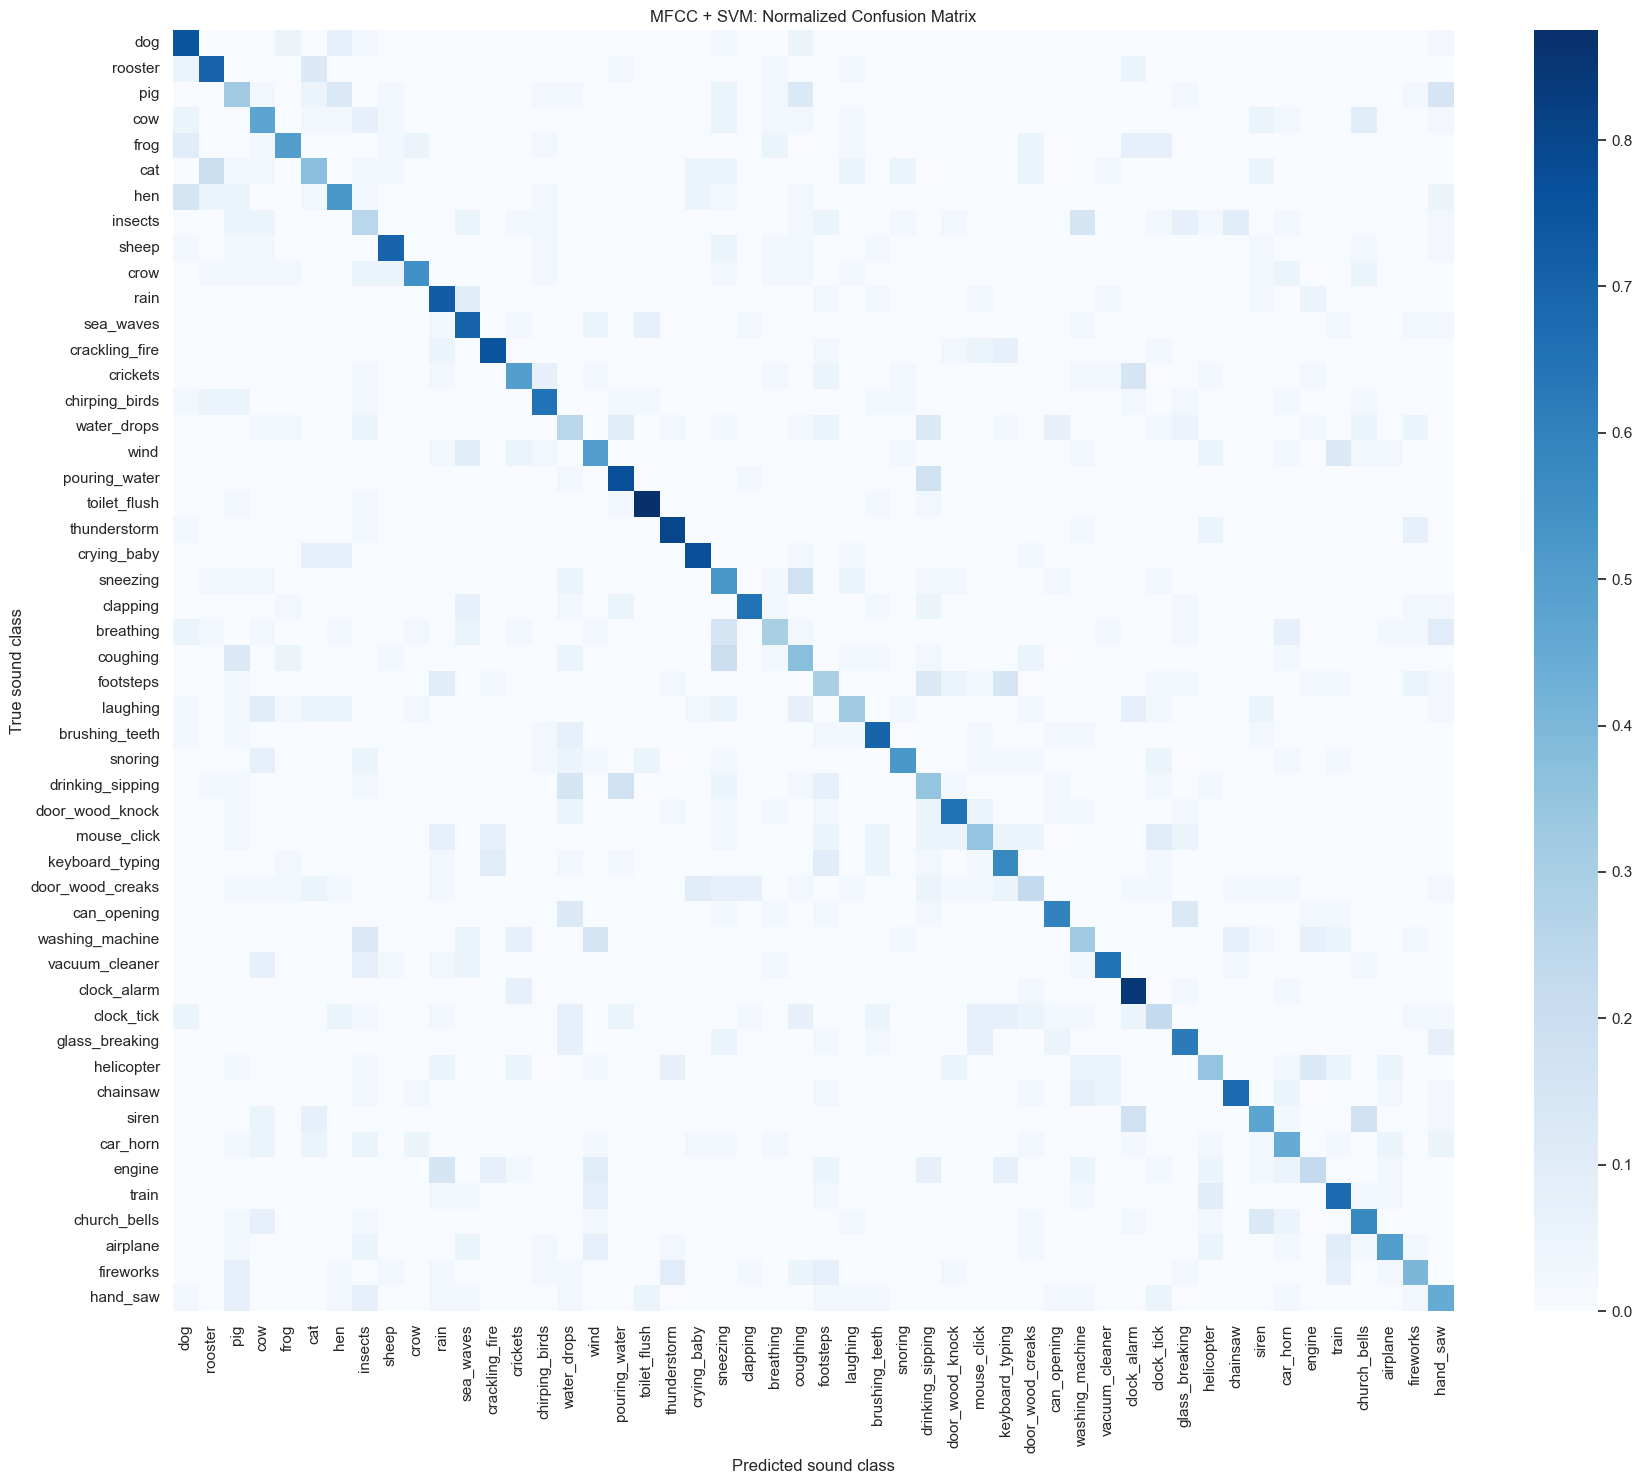

In [44]:
normalized_confusion_matrix = confusion_matrix(
    y,
    all_predictions,
    normalize="true",
)

fig, ax = plt.subplots(
    figsize=(18, 15)
)

sns.heatmap(
    normalized_confusion_matrix,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)

ax.set(
    title="MFCC + SVM: Normalized Confusion Matrix",
    xlabel="Predicted sound class",
    ylabel="True sound class",
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 9. Class-wise F1 scores

An overall accuracy score can hide differences between individual sound classes.

The following graph displays the F1 score for each of the 50 environmental sound classes. Classes with lower F1 scores are more difficult for the MFCC and SVM solution to recognize.

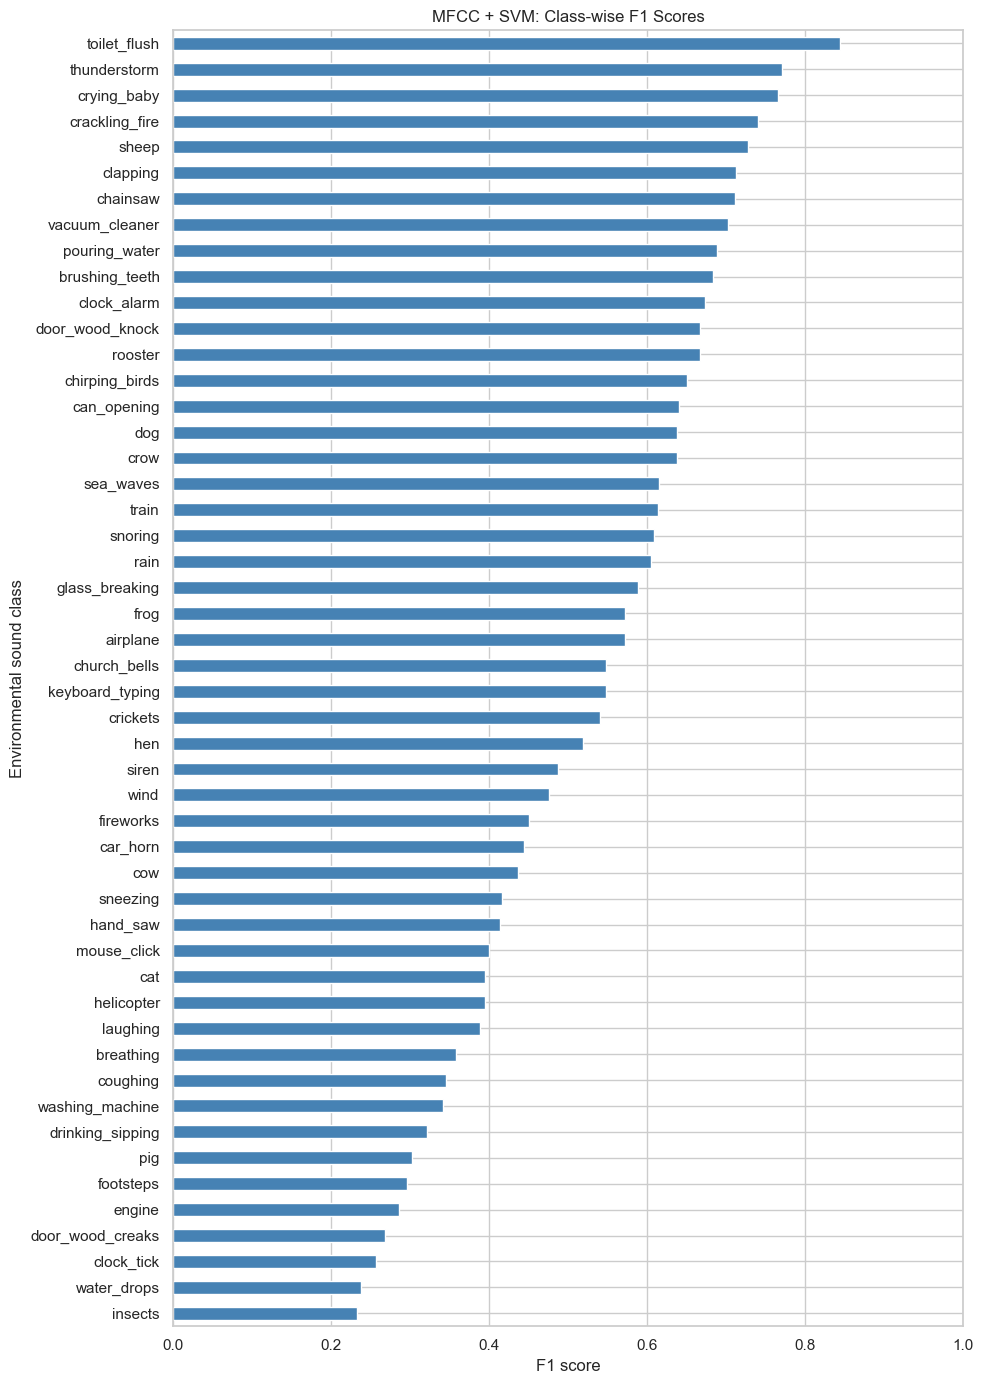

In [45]:
class_f1_scores = (
    report_df
    .loc[class_names, "f1-score"]
    .sort_values()
)

fig, ax = plt.subplots(
    figsize=(10, 14)
)

class_f1_scores.plot.barh(
    ax=ax,
    color="steelblue",
)

ax.set(
    title="MFCC + SVM: Class-wise F1 Scores",
    xlabel="F1 score",
    ylabel="Environmental sound class",
    xlim=(0, 1),
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "classwise_f1.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 10. Interpretation and next step

This experiment establishes the clean-audio baseline for the traditional MFCC and SVM solution.

The model uses handcrafted audio features and therefore provides a useful comparison against the more modern solutions:

1. Spectrogram-based Convolutional Neural Network
2. Pretrained audio embeddings with a classifier

The next stage of the research will evaluate noise robustness.

Controlled background noise will be added to the test recordings at several signal-to-noise ratios:

- 20 dB SNR
- 10 dB SNR
- 5 dB SNR
- 0 dB SNR

The models will not be retrained on the noisy recordings during the initial robustness experiment. This will allow us to measure how much performance decreases when the recording environment changes.

The primary comparison will be an accuracy-versus-SNR graph. Class-wise F1 scores and confusion matrices will also be used to identify which environmental sounds are most affected by noise.

## 11. Noise-robustness experiment

This experiment evaluates how background noise affects the MFCC and SVM environmental sound classifier.

Five recording conditions are evaluated:

- **Clean:** Original ESC-50 recordings without added noise
- **20 dB SNR:** Light background noise
- **10 dB SNR:** Moderate background noise
- **5 dB SNR:** Strong background noise
- **0 dB SNR:** The environmental sound and noise have equal power

The SVM models remain trained on clean audio. Noise is added only to the recordings belonging to each test fold.

Controlled Gaussian broadband noise is used during this initial experiment. A fixed random seed ensures that the same noise is generated whenever the experiment is repeated.

The experiment measures generalization to noisy conditions without retraining the classifier.

In [46]:
NOISE_RANDOM_SEED = 42
SNR_LEVELS = [20, 10, 5, 0]


def load_audio_for_noise_test(
    audio_path,
    sample_rate=SAMPLE_RATE,
):
    """Load, convert to mono, resample and normalize audio."""

    signal, original_rate = sf.read(
        audio_path,
        dtype="float32",
        always_2d=False,
    )

    if signal.ndim == 2:
        signal = signal.mean(axis=1)

    if original_rate != sample_rate:
        common_factor = np.gcd(
            original_rate,
            sample_rate,
        )

        signal = resample_poly(
            signal,
            sample_rate // common_factor,
            original_rate // common_factor,
        )

    peak = np.max(np.abs(signal))

    if peak > 0:
        signal = signal / peak

    return signal.astype(np.float32)


def add_noise_at_snr(
    clean_signal,
    snr_db,
    random_generator,
):
    """
    Add Gaussian noise at a requested signal-to-noise ratio.

    SNR in decibels is:

        10 * log10(signal power / noise power)
    """

    signal_power = np.mean(
        clean_signal ** 2
    )

    if signal_power == 0:
        return clean_signal.copy()

    raw_noise = random_generator.normal(
        loc=0.0,
        scale=1.0,
        size=len(clean_signal),
    ).astype(np.float32)

    raw_noise_power = np.mean(
        raw_noise ** 2
    )

    required_noise_power = (
        signal_power / (10 ** (snr_db / 10.0))
    )

    scaling_factor = np.sqrt(
        required_noise_power / raw_noise_power
    )

    scaled_noise = raw_noise * scaling_factor

    noisy_signal = clean_signal + scaled_noise

    # Prevent clipping while preserving the SNR relationship
    peak = np.max(np.abs(noisy_signal))

    if peak > 1:
        noisy_signal = noisy_signal / peak

    return noisy_signal.astype(np.float32)


def extract_mfcc_from_signal(
    signal,
    sample_rate=SAMPLE_RATE,
    n_mfcc=N_MFCC,
):
    """Extract the same 120 enhanced MFCC features used for clean-audio training."""

    return extract_features_from_signal(
        signal,
        sample_rate=sample_rate,
        n_mfcc=n_mfcc,
    )

# Small verification test
example_signal = load_audio_for_noise_test(
    AUDIO_DIR / metadata.iloc[0]["filename"]
)

example_random_generator = np.random.default_rng(
    NOISE_RANDOM_SEED
)

example_noisy_signal = add_noise_at_snr(
    example_signal,
    snr_db=10,
    random_generator=example_random_generator,
)

example_features = extract_mfcc_from_signal(
    example_noisy_signal
)

print("Clean signal shape:", example_signal.shape)
print("Noisy signal shape:", example_noisy_signal.shape)
print("MFCC feature shape:", example_features.shape)
print("All features are finite:", np.isfinite(example_features).all())

Clean signal shape: (110250,)
Noisy signal shape: (110250,)
MFCC feature shape: (120,)
All features are finite: True


## 12. Extract noisy MFCC features

A separate feature matrix is created for each SNR level.

The generated features are saved in the output folder. If the notebook is run again, the cached features are loaded instead of processing all 2,000 recordings again.

The clean feature matrix calculated earlier is reused as the clean evaluation condition.

In [47]:
noise_feature_sets = {
    "Clean": X
}

for snr_db in SNR_LEVELS:

    cache_path = (
        OUTPUT_DIR
        / ("mfcc_delta_deltadelta_"
           f"guassain_noise_{snr_db}db_v2.npz")
    )

    condition_name = f"{snr_db} dB"

    if cache_path.exists():
        cached_noise_features = np.load(
            cache_path
        )

        noisy_X = cached_noise_features["X"]

        print(
            f"Loaded cached features for {condition_name}"
        )

    else:
        noisy_feature_rows = []

        for recording_index, filename in enumerate(
            tqdm(
                metadata["filename"],
                desc=f"Extracting features at {condition_name}",
            )
        ):
            clean_signal = load_audio_for_noise_test(
                AUDIO_DIR / filename
            )

            # A reproducible but different noise signal
            # is generated for every recording and SNR.
            random_generator = np.random.default_rng(
                NOISE_RANDOM_SEED
                + recording_index
                + (snr_db * 10000)
            )

            noisy_signal = add_noise_at_snr(
                clean_signal,
                snr_db=snr_db,
                random_generator=random_generator,
            )

            noisy_features = extract_mfcc_from_signal(
                noisy_signal
            )

            noisy_feature_rows.append(
                noisy_features
            )

        noisy_X = np.asarray(
            noisy_feature_rows,
            dtype=np.float32,
        )

        np.savez_compressed(
            cache_path,
            X=noisy_X,
        )

        print(
            f"Saved features for {condition_name}:",
            cache_path,
        )

    noise_feature_sets[condition_name] = noisy_X

print("\nAvailable evaluation conditions:")

for condition_name, features in noise_feature_sets.items():
    print(
        condition_name,
        features.shape,
    )

Extracting features at 20 dB:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved features for 20 dB: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm\mfcc_delta_deltadelta_guassain_noise_20db_v2.npz


Extracting features at 10 dB:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved features for 10 dB: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm\mfcc_delta_deltadelta_guassain_noise_10db_v2.npz


Extracting features at 5 dB:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved features for 5 dB: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm\mfcc_delta_deltadelta_guassain_noise_5db_v2.npz


Extracting features at 0 dB:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved features for 0 dB: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm\mfcc_delta_deltadelta_guassain_noise_0db_v2.npz

Available evaluation conditions:
Clean (2000, 120)
20 dB (2000, 120)
10 dB (2000, 120)
5 dB (2000, 120)
0 dB (2000, 120)


## 13. Evaluate the clean-trained SVM under noise

The five SVM models trained earlier are now tested under every noise condition.

Each model is evaluated only on its corresponding official test fold.

No model is retrained using noisy data. Therefore, any reduction in performance represents the model's sensitivity to changes in the recording environment.

In [48]:
condition_order = [
    "Clean",
    "20 dB",
    "10 dB",
    "5 dB",
    "0 dB",
]

noise_results = []
condition_predictions = {}

for condition_name in condition_order:

    condition_X = noise_feature_sets[
        condition_name
    ]

    predictions_for_condition = np.empty_like(y)

    for test_fold in sorted(
        np.unique(folds)
    ):
        test_mask = folds == test_fold

        model = trained_models[
            int(test_fold)
        ]

        fold_predictions = model.predict(
            condition_X[test_mask]
        )

        predictions_for_condition[
            test_mask
        ] = fold_predictions

        noise_results.append(
            {
                "condition": condition_name,
                "fold": int(test_fold),
                "accuracy": accuracy_score(
                    y[test_mask],
                    fold_predictions,
                ),
                "macro_f1": f1_score(
                    y[test_mask],
                    fold_predictions,
                    average="macro",
                    zero_division=0,
                ),
            }
        )

    condition_predictions[
        condition_name
    ] = predictions_for_condition

noise_results = pd.DataFrame(
    noise_results
)

display(
    noise_results.round(4)
)

noise_summary = (
    noise_results
    .groupby("condition", as_index=False)
    .agg(
        mean_accuracy=("accuracy", "mean"),
        standard_deviation_accuracy=(
            "accuracy",
            "std",
        ),
        mean_macro_f1=("macro_f1", "mean"),
        standard_deviation_macro_f1=(
            "macro_f1",
            "std",
        ),
    )
)

noise_summary["condition"] = pd.Categorical(
    noise_summary["condition"],
    categories=condition_order,
    ordered=True,
)

noise_summary = (
    noise_summary
    .sort_values("condition")
    .reset_index(drop=True)
)

display(
    noise_summary.round(4)
)

noise_results.to_csv(
    OUTPUT_DIR / "noise_fold_metrics.csv",
    index=False,
)

noise_summary.to_csv(
    OUTPUT_DIR / "noise_summary.csv",
    index=False,
)

print(
    "Noise results saved to:",
    OUTPUT_DIR,
)

,condition,fold,accuracy,macro_f1
0,Clean,1,0.4750,0.4699
1,Clean,2,0.4750,0.4707
2,Clean,3,0.5650,0.5556
3,Clean,4,0.5950,0.5781
4,Clean,5,0.5250,0.5154
5,20 dB,1,0.3275,0.3014
6,20 dB,2,0.3200,0.2906
7,20 dB,3,0.3400,0.3271
8,20 dB,4,0.3675,0.3359
9,20 dB,5,0.3500,0.3078


,condition,mean_accuracy,standard_deviation_accuracy,mean_macro_f1,standard_deviation_macro_f1
0,Clean,0.5270,0.0536,0.5180,0.0490
1,20 dB,0.3410,0.0188,0.3126,0.0186
2,10 dB,0.1975,0.0215,0.1591,0.0269
3,5 dB,0.1125,0.0133,0.0791,0.0163
4,0 dB,0.0475,0.0061,0.0229,0.0053


Noise results saved to: c:\Users\kashm\OneDrive\Desktop\noise-robust-esc50\outputs\solution1_mfcc_svm


## 14. Accuracy versus signal-to-noise ratio

This graph demonstrates how classification accuracy changes as the background noise becomes stronger.

Moving from clean audio toward 0 dB represents increasingly difficult recording conditions.

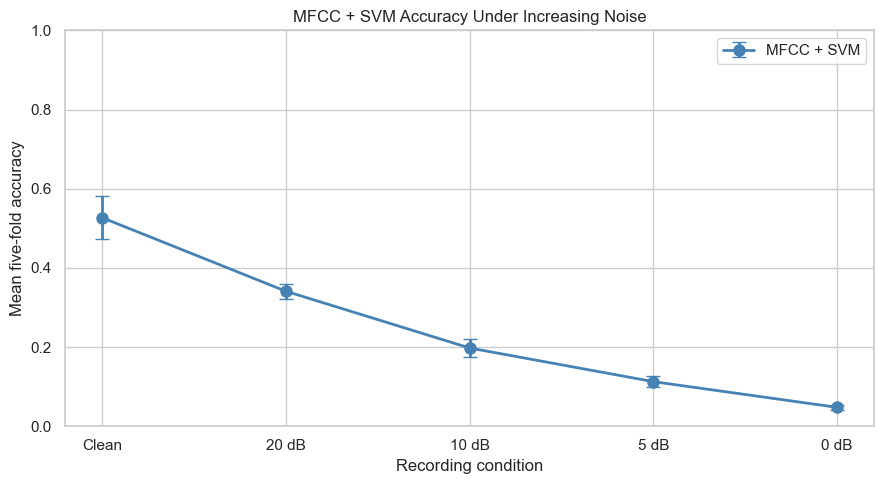

In [49]:
x_positions = np.arange(
    len(condition_order)
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.errorbar(
    x_positions,
    noise_summary["mean_accuracy"],
    yerr=noise_summary[
        "standard_deviation_accuracy"
    ],
    marker="o",
    markersize=8,
    linewidth=2,
    capsize=5,
    color="steelblue",
    label="MFCC + SVM",
)

ax.set_xticks(
    x_positions
)

ax.set_xticklabels(
    condition_order
)

ax.set(
    title="MFCC + SVM Accuracy Under Increasing Noise",
    xlabel="Recording condition",
    ylabel="Mean five-fold accuracy",
    ylim=(0, 1),
)

ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "accuracy_vs_snr.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 15. Macro F1 score versus signal-to-noise ratio

Macro F1 gives equal importance to all 50 environmental sound classes.

Comparing accuracy and macro F1 helps determine whether noise affects only a small number of classes or causes a general decline across the dataset.

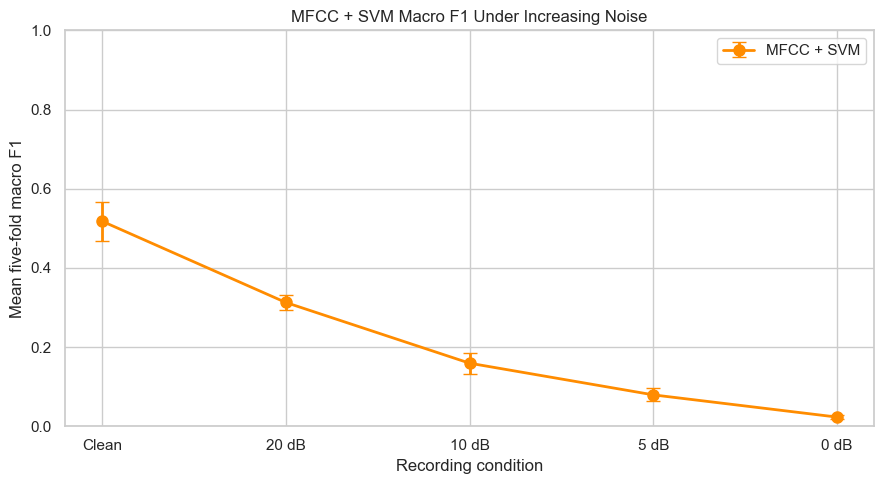

In [51]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.errorbar(
    x_positions,
    noise_summary["mean_macro_f1"],
    yerr=noise_summary[
        "standard_deviation_macro_f1"
    ],
    marker="o",
    markersize=8,
    linewidth=2,
    capsize=5,
    color="darkorange",
    label="MFCC + SVM",
)

ax.set_xticks(
    x_positions
)

ax.set_xticklabels(
    condition_order
)

ax.set(
    title="MFCC + SVM Macro F1 Under Increasing Noise",
    xlabel="Recording condition",
    ylabel="Mean five-fold macro F1",
    ylim=(0, 1),
)

ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "macro_f1_vs_snr.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 16. Class-wise F1 scores under different noise levels

The following heatmap shows how the F1 score of every environmental sound class changes across the five recording conditions.

Darker values represent stronger classification performance. Classes whose values decrease quickly are especially sensitive to background noise.

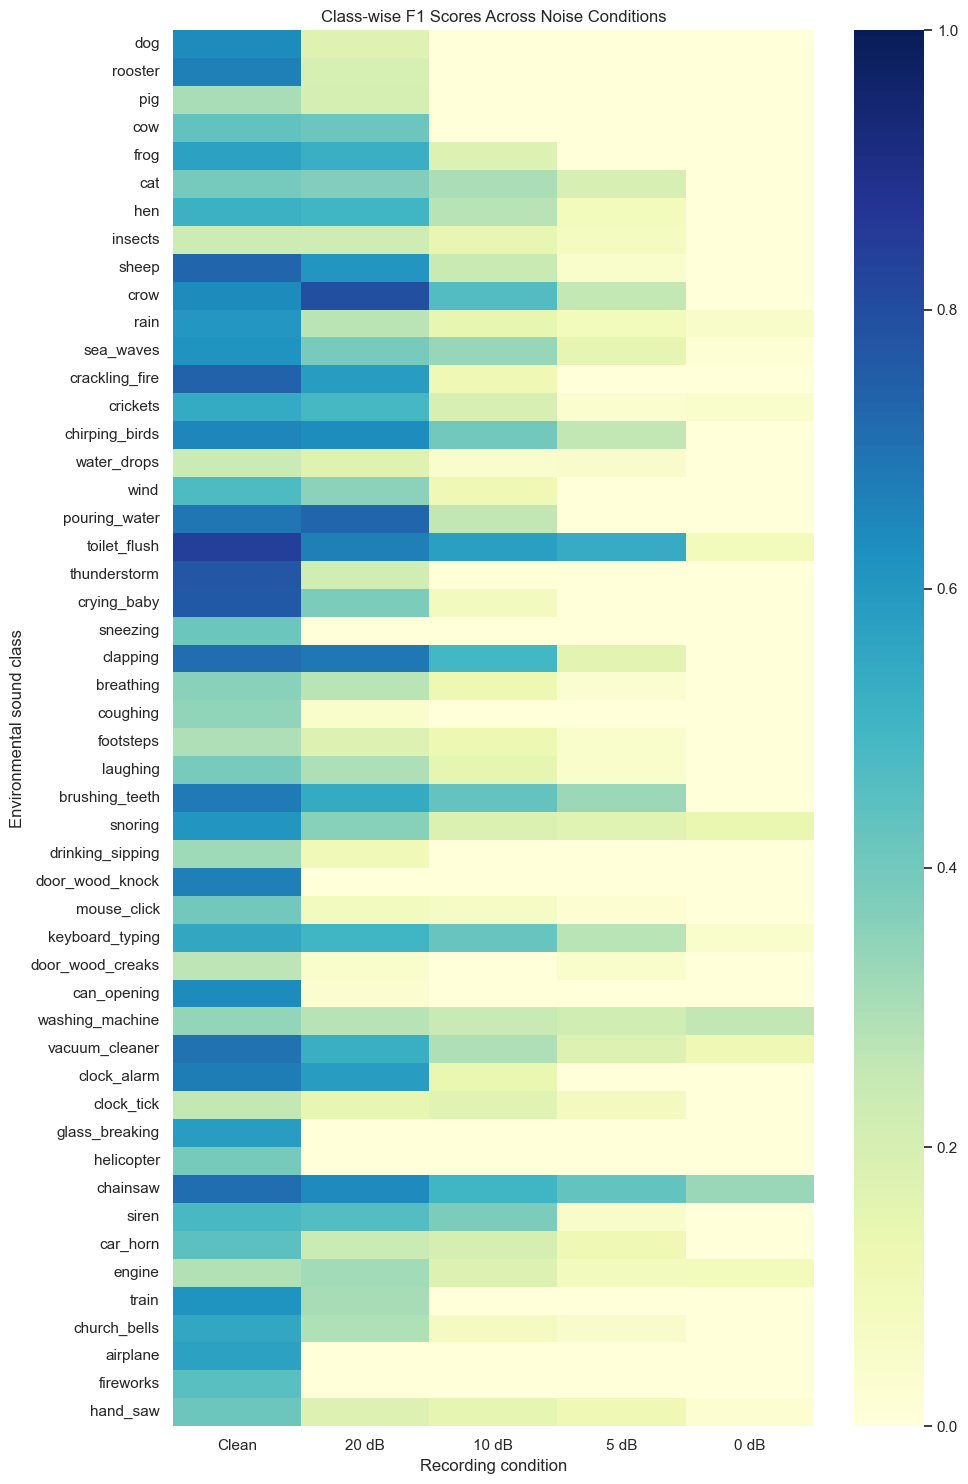

In [52]:
classwise_noise_f1 = pd.DataFrame(
    index=class_names
)

for condition_name in condition_order:

    predictions = condition_predictions[
        condition_name
    ]

    condition_report = classification_report(
        y,
        predictions,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    classwise_noise_f1[
        condition_name
    ] = [
        condition_report[class_name][
            "f1-score"
        ]
        for class_name in class_names
    ]

classwise_noise_f1.to_csv(
    OUTPUT_DIR
    / "classwise_f1_by_noise_condition.csv"
)

fig, ax = plt.subplots(
    figsize=(10, 15)
)

sns.heatmap(
    classwise_noise_f1,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    annot=False,
    ax=ax,
)

ax.set(
    title="Class-wise F1 Scores Across Noise Conditions",
    xlabel="Recording condition",
    ylabel="Environmental sound class",
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "classwise_f1_noise_heatmap.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## 17. Confusion matrices for all noise conditions

These confusion matrices show how classification errors change as background noise becomes stronger.

Comparing the clean and 0 dB matrices makes it possible to identify the class confusions caused by severe noise.

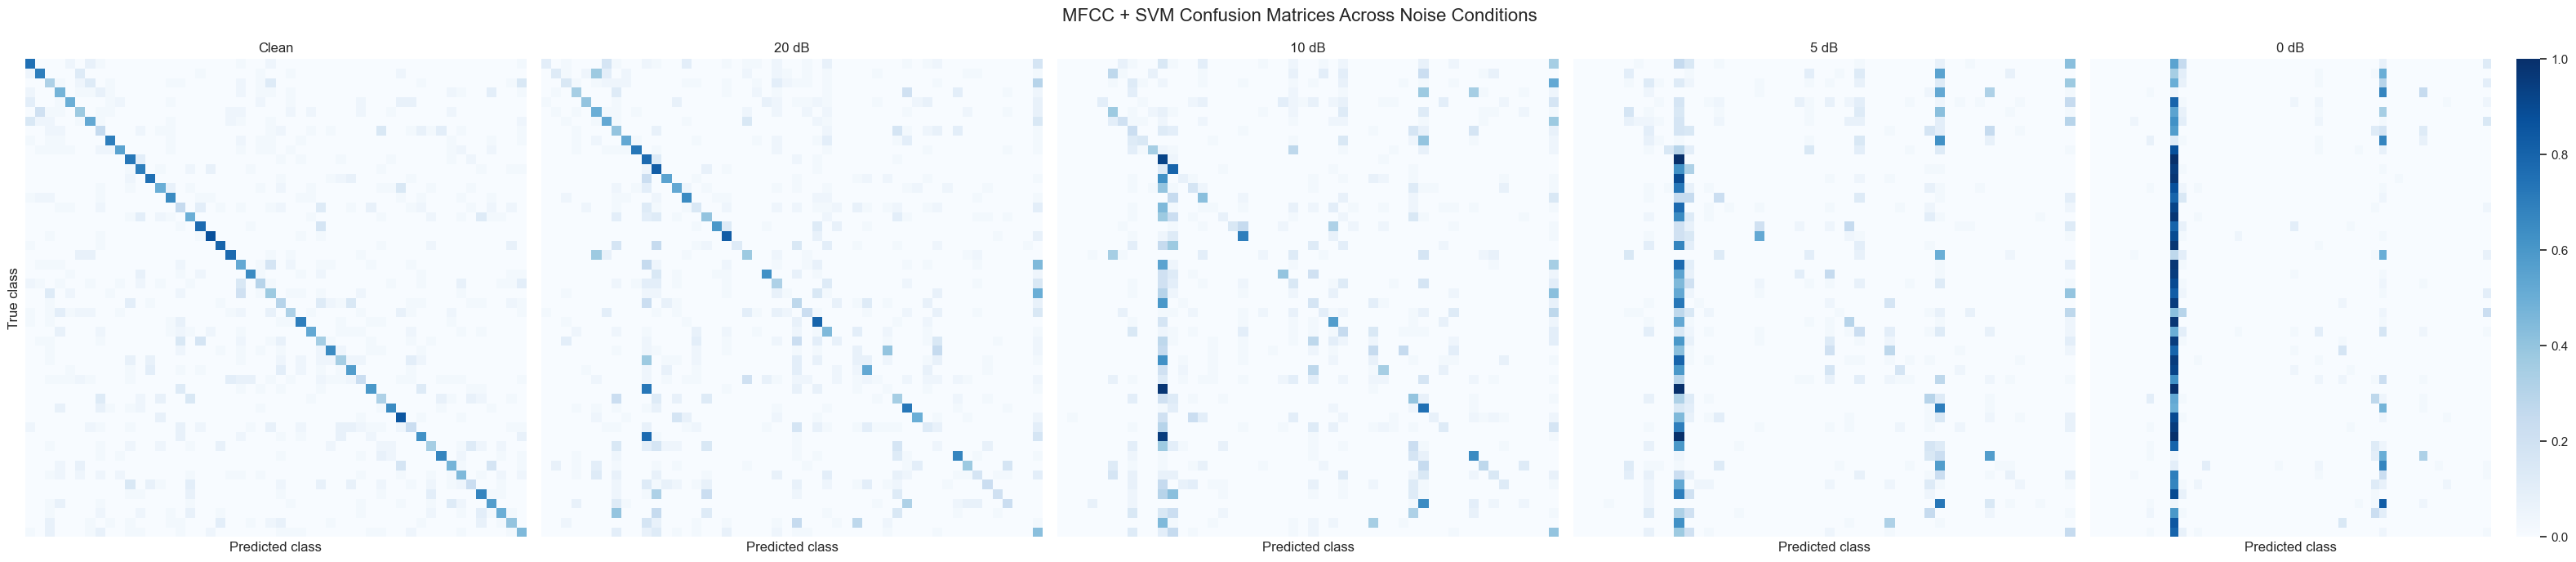

In [53]:
fig, axes = plt.subplots(
    1,
    len(condition_order),
    figsize=(32, 7),
)

for axis, condition_name in zip(
    axes,
    condition_order,
):
    predictions = condition_predictions[
        condition_name
    ]

    matrix = confusion_matrix(
        y,
        predictions,
        normalize="true",
    )

    sns.heatmap(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=False,
        yticklabels=False,
        cbar=condition_name == "0 dB",
        ax=axis,
    )

    axis.set_title(
        condition_name
    )

    axis.set_xlabel(
        "Predicted class"
    )

    if condition_name == "Clean":
        axis.set_ylabel(
            "True class"
        )
    else:
        axis.set_ylabel("")

fig.suptitle(
    "MFCC + SVM Confusion Matrices Across Noise Conditions",
    fontsize=16,
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "confusion_matrices_by_noise.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [54]:
best_parameters_table = pd.DataFrame(
    [
        {
            "fold": fold_number,
            **parameters,
        }
        for fold_number, parameters
        in best_parameters_by_fold.items()
    ]
)

display(
    best_parameters_table
)

best_parameters_table.to_csv(
    OUTPUT_DIR
    / "best_svm_parameters_by_fold.csv",
    index=False,
)

,fold,feature_selection__k,svm__C,svm__gamma
0,1,80,30.0,0.01
1,2,80,10.0,scale
2,3,80,100.0,0.01
3,4,80,10.0,scale
4,5,80,30.0,scale


## 18. Noise-robustness interpretation

The clean condition represents the original ESC-50 classification task.

The 20, 10, 5, and 0 dB conditions progressively increase the amount of background noise while keeping the trained SVM unchanged.

A reduction in accuracy or macro F1 indicates that the handcrafted MFCC representation does not generalize perfectly when recording conditions change.

The difference between clean performance and 0 dB performance can be reported as the model's absolute robustness loss:

#### Robustness loss = Clean accuracy - 0 db accuracy

The same noise conditions should later be applied to the spectrogram CNN and pretrained audio-embedding solutions. This will allow all three approaches to be compared using one accuracy-versus-SNR graph.